# Task 1 — Anti-Cheat Pre-Filter: EDA

สำรวจข้อมูล `data/raw/Task1/` ก่อนสร้างโมเดล ประเด็นหลัก:
1. label ที่หายใน train
2. สัดส่วนคลาส
3. ค่าว่าง (missing) ใน train เทียบกับ test และความสัมพันธ์กับ target
4. feature ใดแยกคนโกงได้ดี และมี interaction หรือไม่

กราฟทั้งหมดถูกบันทึกที่ `reports/figures/task1_*.png` เพื่อใช้ในรายงาน

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "Task1").exists())
DATA = ROOT / "data" / "raw" / "Task1"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Chart style: blue = legitimate (class 0), orange = cheater (class 1)
C_LEGIT, C_CHEAT = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": ["Segoe UI", "Tahoma", "DejaVu Sans"], "figure.dpi": 110,
})

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
FEATURES = [c for c in train.columns if c not in ("player_id", "is_cheater")]
print("train", train.shape, "| test", test.shape, "| features", len(FEATURES))

train (104000, 33) | test (25889, 32) | features 31


## 1. Label และสัดส่วนคลาส

,rows,share
is_cheater,,
Legitimate (0),59091,0.568
Cheater (1),31725,0.305
Missing label,13184,0.127


labeled rows: 90,816  | cheater rate among labeled: 0.349
duplicate player_id: 0 | train/test player_id overlap: 0


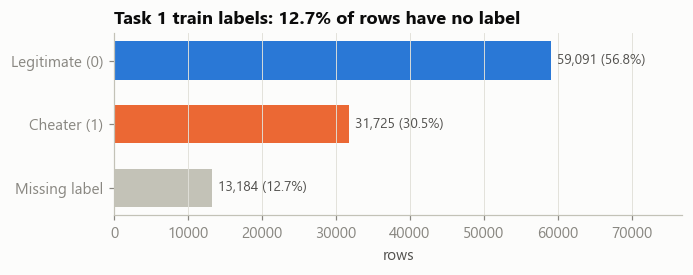

In [2]:
lab = train["is_cheater"].map({0.0: "Legitimate (0)", 1.0: "Cheater (1)"}).fillna("Missing label")
counts = lab.value_counts().reindex(["Legitimate (0)", "Cheater (1)", "Missing label"])
display(pd.DataFrame({"rows": counts, "share": (counts / len(train)).round(3)}))

labeled = train.dropna(subset=["is_cheater"]).reset_index(drop=True)
y = labeled["is_cheater"].astype(int)
print(f"labeled rows: {len(labeled):,}  | cheater rate among labeled: {y.mean():.3f}")
print("duplicate player_id:", train.player_id.duplicated().sum(),
      "| train/test player_id overlap:", len(set(train.player_id) & set(test.player_id)))

fig, ax = plt.subplots(figsize=(6.4, 2.6))
colors = [C_LEGIT, C_CHEAT, "#c3c2b7"]
bars = ax.barh(counts.index[::-1], counts.values[::-1], color=colors[::-1], height=0.6)
for b, v in zip(bars, counts.values[::-1]):
    ax.text(v + 800, b.get_y() + b.get_height() / 2, f"{v:,} ({v / len(train):.1%})",
            va="center", color=INK2, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3); ax.grid(axis="y", visible=False)
ax.set_title("Task 1 train labels: 12.7% of rows have no label")
ax.set_xlabel("rows")
fig.tight_layout(); fig.savefig(FIG / "task1_label_counts.png", bbox_inches="tight"); plt.show()

**สรุป:** 13,184 แถว (12.7%) ไม่มี label จึงตัดออกจากการฝึก ส่วนแถวที่มี label เป็นคนโกง 34.9%
ไม่ได้ไม่สมดุลรุนแรง จึงไม่จำเป็นต้องใช้ SMOTE แต่ต้องเลือก threshold ให้เหมาะกับ F2

## 2. ค่าว่าง (missing values)

rows with >=1 missing value: train 98.2%, test 92.8%


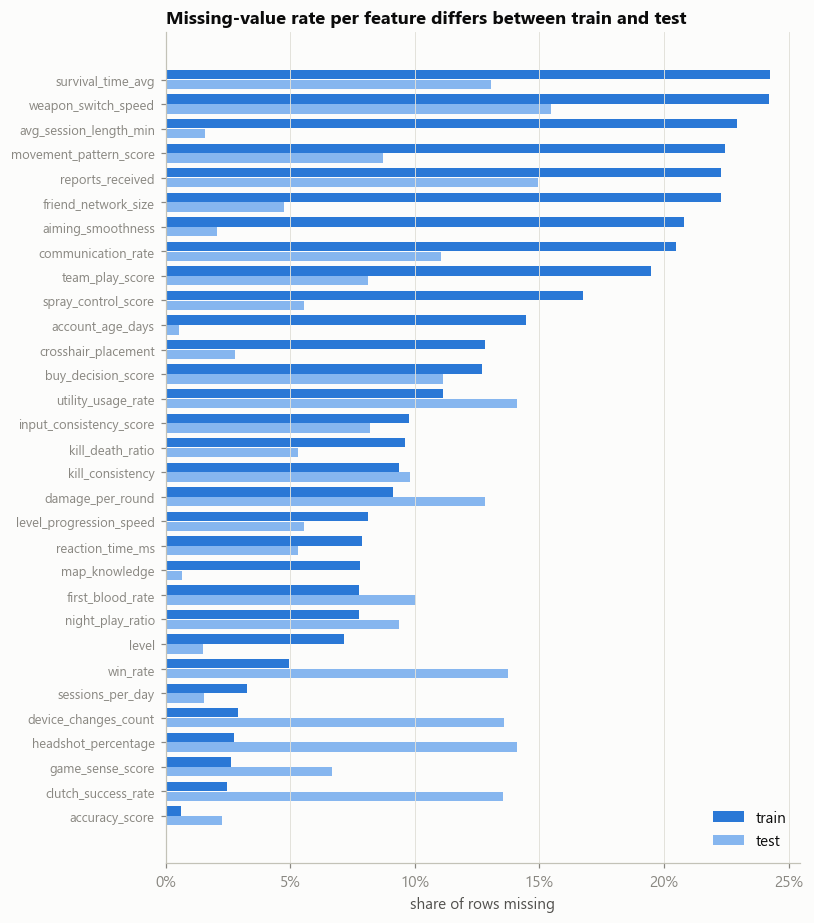

In [3]:
miss = pd.DataFrame({"train": labeled[FEATURES].isna().mean(),
                     "test": test[FEATURES].isna().mean()}).sort_values("train")
print(f"rows with >=1 missing value: train {labeled[FEATURES].isna().any(axis=1).mean():.1%}, "
      f"test {test[FEATURES].isna().any(axis=1).mean():.1%}")

fig, ax = plt.subplots(figsize=(7.5, 8.5))
pos = np.arange(len(miss)); h = 0.38
ax.barh(pos + h / 2 + 0.01, miss["train"], height=h, color=C_LEGIT, label="train")
ax.barh(pos - h / 2 - 0.01, miss["test"], height=h, color="#86b6ef", label="test")
ax.set_yticks(pos, miss.index, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Missing-value rate per feature differs between train and test")
ax.set_xlabel("share of rows missing"); ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "task1_missing_rates.png", bbox_inches="tight"); plt.show()

In [4]:
# Does missingness carry signal about the label?
rate = pd.DataFrame({
    "cheater_rate_if_missing": {c: y[labeled[c].isna()].mean() for c in FEATURES},
    "cheater_rate_if_present": {c: y[labeled[c].notna()].mean() for c in FEATURES},
})
rate["diff"] = rate.iloc[:, 0] - rate.iloc[:, 1]
display(rate.sort_values("diff").round(3).iloc[[0, 1, 2, -3, -2, -1]])
print("corr(#missing per row, label) =", round(np.corrcoef(labeled[FEATURES].isna().sum(axis=1), y)[0, 1], 4))

,cheater_rate_if_missing,cheater_rate_if_present,diff
game_sense_score,0.339,0.350,-0.010
level_progression_speed,0.343,0.350,-0.007
clutch_success_rate,0.343,0.349,-0.006
aiming_smoothness,0.356,0.348,0.008
spray_control_score,0.357,0.348,0.009
buy_decision_score,0.359,0.348,0.011


corr(#missing per row, label) = 0.0037


**สรุป:** เกือบทุกแถวมีค่าว่างอย่างน้อย 1 คอลัมน์ และสัดส่วนค่าว่างใน train กับ test ต่างกันมาก
(เช่น `account_age_days` ว่าง 14% ใน train แต่ 0.6% ใน test) แต่อัตราคนโกงแทบเท่ากัน (~0.35)
ไม่ว่าค่าจะว่างหรือไม่ แปลว่าค่าว่างเกิดแบบสุ่ม (MCAR) จึง**ไม่สร้าง missing indicator**
เพราะจะไม่ช่วยและเสี่ยงต่อ distribution shift ระหว่าง train/test
และปล่อยให้ LightGBM/XGBoost จัดการ NaN เอง

## 3. Feature ใดแยกคนโกงได้

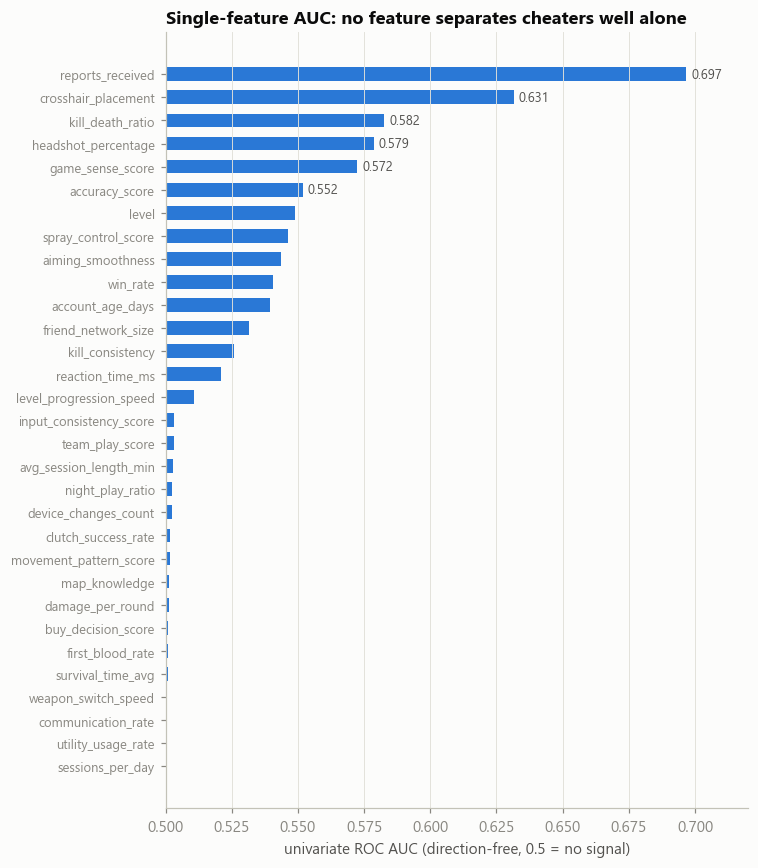

direction (AUC > 0.5 means higher value -> more likely cheater):


,auc
reports_received,0.303
crosshair_placement,0.369
kill_death_ratio,0.418
headshot_percentage,0.421
game_sense_score,0.428
accuracy_score,0.448
level,0.451
spray_control_score,0.454


In [5]:
def uni_auc(c):
    m = labeled[c].notna()
    return roc_auc_score(y[m], labeled.loc[m, c])

auc = pd.Series({c: uni_auc(c) for c in FEATURES})
strength = (auc - 0.5).abs().sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(strength.index, strength.values, left=0.5, color=C_LEGIT, height=0.6)
ax.set_xlim(0.5, 0.72); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
for i, (c, v) in enumerate(strength.items()):
    if i >= len(strength) - 6:
        ax.text(v + 0.5 + 0.002, i, f"{v + 0.5:.3f}", va="center", fontsize=8.5, color=INK2)
ax.set_title("Single-feature AUC: no feature separates cheaters well alone")
ax.set_xlabel("univariate ROC AUC (direction-free, 0.5 = no signal)")
fig.tight_layout(); fig.savefig(FIG / "task1_univariate_auc.png", bbox_inches="tight"); plt.show()
print("direction (AUC > 0.5 means higher value -> more likely cheater):")
display(auc[strength.index[::-1][:8]].round(3).to_frame("auc"))

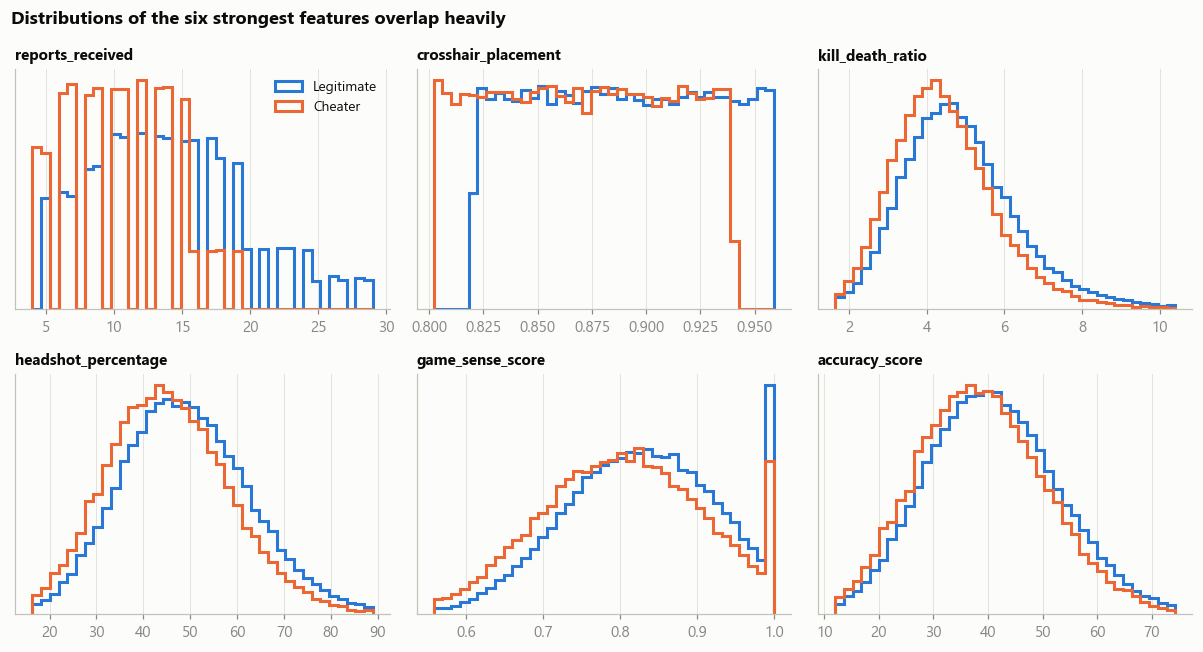

In [6]:
top = list(strength.index[::-1][:6])
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, c in zip(axes.ravel(), top):
    lo, hi = labeled[c].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 40)
    for cls, col, name in [(0, C_LEGIT, "Legitimate"), (1, C_CHEAT, "Cheater")]:
        ax.hist(labeled.loc[y == cls, c].dropna(), bins=bins, density=True, histtype="step",
                linewidth=2, color=col, label=name)
    ax.set_title(c, fontsize=10); ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("Distributions of the six strongest features overlap heavily", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "task1_top_feature_dists.png", bbox_inches="tight"); plt.show()

**สรุป:** feature เดี่ยวที่แยกได้ดีที่สุดคือ `reports_received` (AUC ~0.70) รองลงมาคือ
`crosshair_placement`, `kill_death_ratio`, `headshot_percentage` แต่ distribution ของสองคลาสซ้อนกันมาก
ไม่มี feature ไหนแยกได้ชัดเพียงตัวเดียว

## 4. ช่วงค่าที่พบเฉพาะคลาสเดียว

กราฟ `crosshair_placement` ด้านบนแสดงขอบเขตที่ชัดเจน: คนโกงอยู่ในช่วง 0.80–0.94 ส่วนผู้เล่นปกติอยู่ในช่วง 0.82–0.96
ตรวจทุก feature ว่ามีช่วงค่าที่พบเฉพาะคลาสเดียวหรือไม่

In [7]:
rows = []
only_legit = np.zeros(len(labeled), bool); only_cheat = np.zeros(len(labeled), bool)
for c in FEATURES:
    lo0, hi0 = labeled.loc[y == 0, c].min(), labeled.loc[y == 0, c].max()
    lo1, hi1 = labeled.loc[y == 1, c].min(), labeled.loc[y == 1, c].max()
    in_l = ((labeled[c] < lo1) | (labeled[c] > hi1)).values   # outside the cheater range
    in_c = ((labeled[c] < lo0) | (labeled[c] > hi0)).values   # outside the legit range
    only_legit |= in_l; only_cheat |= in_c
    if in_l.mean() + in_c.mean() > 0.001:
        rows.append({"feature": c, "legit range": f"{lo0:.3g} – {hi0:.3g}", "cheater range": f"{lo1:.3g} – {hi1:.3g}",
                     "rows only-legit": f"{in_l.mean():.1%}", "rows only-cheater": f"{in_c.mean():.1%}"})
display(pd.DataFrame(rows))
print(f"rows with any legit-only value: {only_legit.mean():.1%} | any cheater-only value: {only_cheat.mean():.1%} | "
      f"both: {(only_legit & only_cheat).sum()}")

,feature,legit range,cheater range,rows only-legit,rows only-cheater
0,account_age_days,1.01 – 1.5e+03,15 – 1e+03,7.9%,0.0%
1,level,28 – 100,25 – 96,3.4%,1.3%
2,level_progression_speed,0.00293 – 80,0.00435 – 6.25,0.7%,0.0%
3,friend_network_size,0 – 349,10 – 269,6.5%,0.0%
4,reports_received,5 – 29,4 – 19,8.3%,1.6%
5,crosshair_placement,0.82 – 0.96,0.8 – 0.94,8.1%,4.3%


rows with any legit-only value: 26.3% | any cheater-only value: 6.9% | both: 0


**สรุป:** มี 6 feature ที่มีช่วงค่าเฉพาะคลาส เช่น บัญชีอายุเกิน 1,000 วัน เพื่อนเกิน 269 คน หรือได้รับรายงานเกิน 19 ครั้ง
พบเฉพาะในผู้เล่นปกติ ส่วน `crosshair_placement` ต่ำกว่า 0.82 พบเฉพาะในคนโกง
ประมาณ 26% ของแถวมีค่าในช่วงเฉพาะผู้เล่นปกติ และ 7% มีค่าในช่วงเฉพาะคนโกง โดยไม่มีแถวไหนขัดกันเอง
tree model เรียนรู้ขอบเขตแบบนี้ได้ด้วย split เดียว จึงเป็นเหตุผลหนึ่งที่ tree ทำได้ดีกว่าโมเดลเชิงเส้นมาก

ข้อสังเกตเพิ่มเติม: ภายในแต่ละคลาส feature เกือบทั้งหมดแทบไม่สัมพันธ์กัน (|Spearman ρ| เฉลี่ย ~0.02)
ยกเว้นกลุ่ม `account_age_days`–`level_progression_speed`–`friend_network_size`–`level`
(`level_progression_speed` ≈ `level / account_age_days` × ตัวคูณสุ่ม 0.15–1.08)

## 5. Interaction: โมเดลเชิงเส้นเทียบกับ tree

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb

X = labeled[FEATURES]
cv = StratifiedKFold(5, shuffle=True, random_state=42)
p_lr = cross_val_predict(make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                       LogisticRegression(max_iter=2000)), X, y, cv=cv, method="predict_proba")[:, 1]
p_gb = cross_val_predict(lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, verbose=-1, random_state=42),
                         X, y, cv=cv, method="predict_proba")[:, 1]
print(f"5-fold AUC  logistic regression: {roc_auc_score(y, p_lr):.4f}   LightGBM: {roc_auc_score(y, p_gb):.4f}")

5-fold AUC  logistic regression: 0.7649   LightGBM: 0.8906


**สรุป:** LightGBM ได้ AUC สูงกว่า logistic regression มาก (~0.89 เทียบกับ ~0.76)
ทั้งที่ feature แต่ละตัวแยกได้ไม่ดี แสดงว่าสัญญาณส่วนใหญ่อยู่ใน **interaction / ความสัมพันธ์ไม่เชิงเส้น**
ระหว่าง feature จึงเลือกใช้ gradient boosting เป็นโมเดลหลัก
ผลโมเดลสุดท้ายและการเลือก threshold อยู่ใน `02_model_analysis.ipynb`